# Decoder Latency and Backlog Modelling

A fault-tolerant quantum computer generates syndrome data continuously, requiring the classical decoder to process each record quickly enough to prevent unbounded backlog accumulation.

### Queueing Model Formulation
This notebook models the real-time decoding pipeline as a discrete-arrival queueing system in which:
* **Arrival Process:** Syndrome windows arrive at deterministic, fixed cycle intervals ($\tau_{\mathrm{round}}$).
* **Service Distribution:** Each syndrome window requires a variable decoding time governed by syndrome weight and graph complexity.
* **Parallel Execution:** One or more parallel classical workers process incoming windows from the queue.
* **Deadline Criterion:** A real-time deadline is missed whenever a window's completion time exceeds its maximum allowed response latency.

### Key Performance Metrics
To evaluate real-time feasibility, the analysis distinguishes between:
* Aggregate batch throughput vs. single-shot decoding latency;
* Queue stability conditions (arrival rate vs. effective service rate);
* Tail-latency behaviour (e.g., $99\text{th}$ and $99.9\text{th}$ percentile response times);
* Transient and unbounded backlog growth;
* Minimum parallel worker count required to sustain real-time operation.

Crucially, a decoder can achieve high offline batch throughput while still violating strict per-round real-time latency constraints.


In [2]:
# Easier way to work with files and directories
from pathlib import Path

# High-resolution timer for benchmarking execution speed
from time import perf_counter

# --- Data Handling & Numerical Operations ---
# Creates plots and figures
import matplotlib.pyplot as plt
# Provides arrays and numerical operations
import numpy as np
import pandas as pd

# --- Quantum Error Correction Simulation & Decoding ---
# Minimum-Weight Perfect Matching (MWPM) decoder for syndrome decoding
import pymatching
# Fast stabilizer circuit simulator and noise sampler
import stim

PROJECT_DIR = Path(
    r"C:\Users\Karthi\Qauntum"
).resolve()

FIGURE_DIR = PROJECT_DIR / "figures"
RESULTS_DIR = PROJECT_DIR / "results"

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

SEED = 42

print(f"Project directory: {PROJECT_DIR}")
print("Decoder latency environment ready")

Project directory: C:\Users\Karthi\Qauntum
Decoder latency environment ready


In [3]:
# Constants for surface-code circuit
CODE_DISTANCE = 7
SYNDROME_ROUNDS = 7
PHYSICAL_ERROR_PROBABILITY = 0.005
BENCHMARK_SHOTS = 20_000


In [4]:
# Create circuit
benchmark_circuit = stim.Circuit.generated(
    "surface_code:rotated_memory_x",
    distance=CODE_DISTANCE,
    rounds=SYNDROME_ROUNDS,
    after_clifford_depolarization=(
        PHYSICAL_ERROR_PROBABILITY
    ),
    before_round_data_depolarization=(
        PHYSICAL_ERROR_PROBABILITY
    ),
    before_measure_flip_probability=(
        PHYSICAL_ERROR_PROBABILITY
    ),
    after_reset_flip_probability=(
        PHYSICAL_ERROR_PROBABILITY
    ),
)

print(
    f"Qubits: {benchmark_circuit.num_qubits}"
)

print(
    f"Detectors: {benchmark_circuit.num_detectors}"
)

print(
    f"Measurements: "
    f"{benchmark_circuit.num_measurements}"
)

Qubits: 118
Detectors: 336
Measurements: 385


In [5]:
# Build decoder
detector_error_model = (
    benchmark_circuit.detector_error_model(
        decompose_errors=True
    )
)

decoder = (
    pymatching.Matching
    .from_detector_error_model(
        detector_error_model
    )
)

sampler = (
    benchmark_circuit
    .compile_detector_sampler(
        seed=SEED
    )
)

print(
    f"Matching-graph edges: "
    f"{decoder.num_edges}"
)

Matching-graph edges: 1558


In [6]:
# Generate detector samples
detection_events, actual_observables = (
    sampler.sample(
        shots=BENCHMARK_SHOTS,
        separate_observables=True,
    )
)

print(
    "Detector sample shape:",
    detection_events.shape,
)

print(
    "Observable sample shape:",
    actual_observables.shape,
)

Detector sample shape: (20000, 336)
Observable sample shape: (20000, 1)


In [7]:
# Decoder warm-up
decoder.decode_batch(
    detection_events[:10]
)

print("Decoder warm-up complete")

Decoder warm-up complete


In [8]:
# Measure batch performance
# Run several repeats so that one timing fluctuation does not determine the result
BATCH_TIMING_REPEATS = 10

batch_timing_results = []

for repeat_index in range(
    BATCH_TIMING_REPEATS
):
    start_time = perf_counter()

    predicted_observables = (
        decoder.decode_batch(
            detection_events
        )
    )

    end_time = perf_counter()

    elapsed_seconds = (
        end_time - start_time
    )

    batch_timing_results.append(
        {
            "repeat": repeat_index,
            "shots": BENCHMARK_SHOTS,
            "elapsed_seconds": (
                elapsed_seconds
            ),
            "shots_per_second": (
                BENCHMARK_SHOTS
                / elapsed_seconds
            ),
            "microseconds_per_shot": (
                1e6
                * elapsed_seconds
                / BENCHMARK_SHOTS
            ),
        }
    )

In [9]:
# Display results
batch_timing_df = pd.DataFrame(
    batch_timing_results
)

batch_timing_df


,repeat,shots,elapsed_seconds,shots_per_second,microseconds_per_shot
0,0,20000,0.124582,160537.092801,6.229090
1,1,20000,0.126462,158150.274300,6.323100
2,2,20000,0.125846,158924.147043,6.292310
3,3,20000,0.126466,158144.772063,6.323320
4,4,20000,0.124149,161097.265800,6.207430
5,5,20000,0.124647,160453.634533,6.232330
6,6,20000,0.124876,160158.492858,6.243815
7,7,20000,0.126572,158012.206464,6.328625
8,8,20000,0.126723,157824.546351,6.336150
9,9,20000,0.125647,159176.231270,6.282345


In [10]:
# Create Summary
batch_timing_summary = {
    "mean_microseconds_per_shot": float(
        batch_timing_df[
            "microseconds_per_shot"
        ].mean()
    ),
    "median_microseconds_per_shot": float(
        batch_timing_df[
            "microseconds_per_shot"
        ].median()
    ),
    "minimum_microseconds_per_shot": float(
        batch_timing_df[
            "microseconds_per_shot"
        ].min()
    ),
    "maximum_microseconds_per_shot": float(
        batch_timing_df[
            "microseconds_per_shot"
        ].max()
    ),
    "mean_shots_per_second": float(
        batch_timing_df[
            "shots_per_second"
        ].mean()
    ),
}

pd.Series(batch_timing_summary)

mean_microseconds_per_shot            6.279852
median_microseconds_per_shot          6.287327
minimum_microseconds_per_shot         6.207430
maximum_microseconds_per_shot         6.336150
mean_shots_per_second            159247.866348
dtype: float64

In [11]:
# Confirm decoding correctness
decoding_failures = np.any(
    predicted_observables
    != actual_observables,
    axis=1,
)

logical_failure_count = int(
    decoding_failures.sum()
)

logical_failure_probability = (
    logical_failure_count
    / BENCHMARK_SHOTS
)

print(
    f"Logical failures: "
    f"{logical_failure_count:,}"
)

print(
    f"Logical failure probability: "
    f"{logical_failure_probability:.6e}"
)

Logical failures: 237
Logical failure probability: 1.185000e-02


In [12]:
# Keep the measurement manageable
SINGLE_SHOT_BENCHMARKS = 5_000

single_shot_samples = detection_events[
    :SINGLE_SHOT_BENCHMARKS
]

In [13]:
# Warm up
for sample in single_shot_samples[:100]:
    decoder.decode(sample)

In [14]:
# Measure each call
single_shot_results = []

for shot_index, detector_sample in enumerate(
    single_shot_samples
):
    event_count = int(
        detector_sample.sum()
    )

    start_time = perf_counter()

    decoder.decode(
        detector_sample
    )

    end_time = perf_counter()

    elapsed_microseconds = (
        1e6
        * (
            end_time - start_time
        )
    )

    single_shot_results.append(
        {
            "shot_index": shot_index,
            "detection_events": (
                event_count
            ),
            "latency_microseconds": (
                elapsed_microseconds
            ),
        }
    )

In [15]:
# Convert to a table
single_shot_latency_df = pd.DataFrame(
    single_shot_results
)

single_shot_latency_df.head()

,shot_index,detection_events,latency_microseconds
0,0,25,56.600082
1,1,25,18.300023
2,2,36,24.799956
3,3,19,14.199992
4,4,27,13.699988


In [16]:
# Latency distribution summary
latency_summary = {
    "samples": len(
        single_shot_latency_df
    ),
    "mean_microseconds": float(
        single_shot_latency_df[
            "latency_microseconds"
        ].mean()
    ),
    "median_microseconds": float(
        single_shot_latency_df[
            "latency_microseconds"
        ].median()
    ),
    "p90_microseconds": float(
        single_shot_latency_df[
            "latency_microseconds"
        ].quantile(0.90)
    ),
    "p95_microseconds": float(
        single_shot_latency_df[
            "latency_microseconds"
        ].quantile(0.95)
    ),
    "p99_microseconds": float(
        single_shot_latency_df[
            "latency_microseconds"
        ].quantile(0.99)
    ),
    "p999_microseconds": float(
        single_shot_latency_df[
            "latency_microseconds"
        ].quantile(0.999)
    ),
    "maximum_microseconds": float(
        single_shot_latency_df[
            "latency_microseconds"
        ].max()
    ),
}

pd.Series(latency_summary)

samples                 5000.000000
mean_microseconds         10.585680
median_microseconds        9.250012
p90_microseconds          15.800004
p95_microseconds          19.205024
p99_microseconds          28.800986
p999_microseconds        100.423566
maximum_microseconds     183.500000
dtype: float64

In [17]:
# Plot the distribution
# Exclude only the most extreme 0.1% from the main histogram so that the central distribution remains visible
histogram_limit = (
    single_shot_latency_df[
        "latency_microseconds"
    ].quantile(0.999)
)

histogram_data = single_shot_latency_df[
    single_shot_latency_df[
        "latency_microseconds"
    ] <= histogram_limit
]

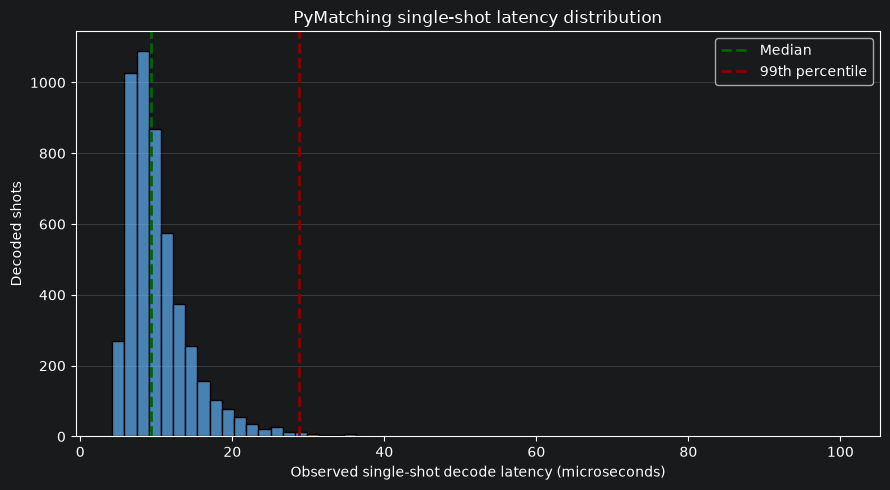

In [18]:
# Plot
figure, axis = plt.subplots(
    figsize=(9, 5)
)

axis.hist(
    histogram_data[
        "latency_microseconds"
    ],
    bins=60,
    color="steelblue",
    edgecolor="black",
)

axis.axvline(
    latency_summary[
        "median_microseconds"
    ],
    color="darkgreen",
    linestyle="--",
    linewidth=2,
    label="Median",
)

axis.axvline(
    latency_summary[
        "p99_microseconds"
    ],
    color="darkred",
    linestyle="--",
    linewidth=2,
    label="99th percentile",
)

axis.set_xlabel(
    "Observed single-shot decode latency "
    "(microseconds)"
)

axis.set_ylabel(
    "Decoded shots"
)

axis.set_title(
    "PyMatching single-shot latency distribution"
)

axis.grid(
    axis="y",
    alpha=0.3,
)

axis.legend()

figure.tight_layout()

latency_distribution_path = (
    FIGURE_DIR
    / "decoder_latency_distribution.png"
)

figure.savefig(
    latency_distribution_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

In [19]:
# Calculate correlations
pearson_correlation = (
    single_shot_latency_df[
        [
            "detection_events",
            "latency_microseconds",
        ]
    ]
    .corr(
        method="pearson"
    )
    .iloc[0, 1]
)

spearman_correlation = (
    single_shot_latency_df[
        [
            "detection_events",
            "latency_microseconds",
        ]
    ]
    .corr(
        method="spearman"
    )
    .iloc[0, 1]
)

print(
    f"Pearson correlation: "
    f"{pearson_correlation:.4f}"
)

print(
    f"Spearman correlation: "
    f"{spearman_correlation:.4f}"
)

Pearson correlation: 0.4116
Spearman correlation: 0.7258


In [20]:
# Group latency by event count
event_latency_summary_df = (
    single_shot_latency_df
    .groupby(
        "detection_events"
    )
    .agg(
        samples=(
            "latency_microseconds",
            "size",
        ),
        mean_latency_microseconds=(
            "latency_microseconds",
            "mean",
        ),
        median_latency_microseconds=(
            "latency_microseconds",
            "median",
        ),
        p95_latency_microseconds=(
            "latency_microseconds",
            lambda values: values.quantile(
                0.95
            ),
        ),
        p99_latency_microseconds=(
            "latency_microseconds",
            lambda values: values.quantile(
                0.99
            ),
        ),
    )
    .reset_index()
)

event_latency_summary_df.head(20)

,detection_events,samples,mean_latency_microseconds,median_latency_microseconds,p95_latency_microseconds,p99_latency_microseconds
0,5,3,4.999960,4.599919,5.770032,5.874042
1,6,4,4.999951,4.499918,6.469933,6.733935
2,7,8,4.749993,4.549976,5.554967,5.750936
3,8,12,5.399993,5.049980,6.634986,6.767039
4,9,14,6.471428,5.149981,12.465054,19.693049
5,10,39,5.630770,5.200040,7.110042,10.361962
6,11,32,6.659364,5.550042,8.850003,20.094992
7,12,44,6.620473,5.899987,10.400079,11.013018
8,13,85,6.297637,5.799928,8.820044,11.928091
9,14,79,7.030385,6.200047,10.309974,21.060044


In [21]:
# Filter groups with enough samples to be meaningful
reliable_event_groups_df = (
    event_latency_summary_df[
        event_latency_summary_df[
            "samples"
        ] >= 20
    ]
)

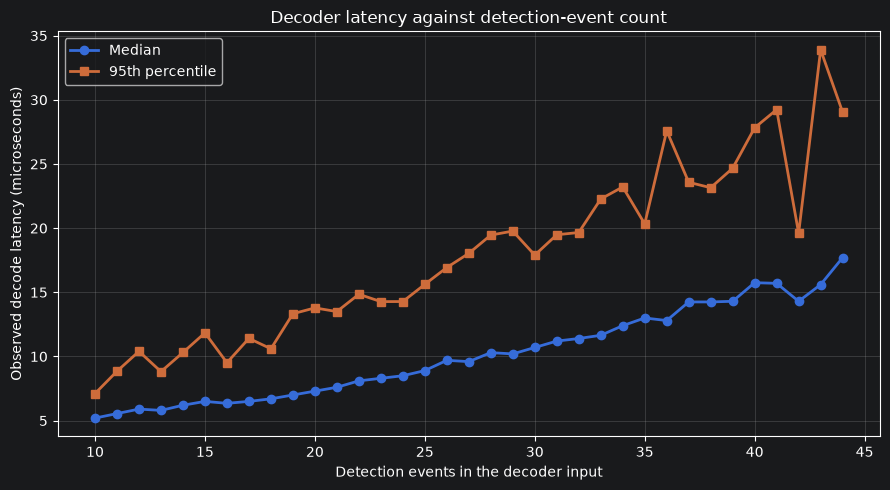

In [22]:
# Plot
figure, axis = plt.subplots(
    figsize=(9, 5)
)

axis.plot(
    reliable_event_groups_df[
        "detection_events"
    ],
    reliable_event_groups_df[
        "median_latency_microseconds"
    ],
    marker="o",
    linewidth=2,
    label="Median",
)

axis.plot(
    reliable_event_groups_df[
        "detection_events"
    ],
    reliable_event_groups_df[
        "p95_latency_microseconds"
    ],
    marker="s",
    linewidth=2,
    label="95th percentile",
)

axis.set_xlabel(
    "Detection events in the decoder input"
)

axis.set_ylabel(
    "Observed decode latency "
    "(microseconds)"
)

axis.set_title(
    "Decoder latency against detection-event count"
)

axis.grid(
    True,
    alpha=0.3,
)

axis.legend()

figure.tight_layout()

event_latency_path = (
    FIGURE_DIR
    / "decoder_latency_vs_detection_events.png"
)

figure.savefig(
    event_latency_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

# Real-Time Decoder Queue

Each syndrome window is modelled as a discrete job arriving at a classical decoder.

For a single decoder worker, the server utilisation $\rho$ is given by:

$$
\rho = \frac{\mathbb{E}[S]}{\tau_{\mathrm{arr}}}
$$

where $\mathbb{E}[S]$ is the mean service time and $\tau_{\mathrm{arr}}$ is the syndrome-window arrival interval.

* **Stability ($\rho < 1$):** The decoder processes jobs faster on average than they arrive, allowing the queue to remain bounded and periodically return to zero backlog.
* **Instability ($\rho > 1$):** Syndrome windows arrive faster than the worker can clear them, causing unbounded backlog growth over time.

However, low mean utilisation ($\rho \ll 1$) does not by itself guarantee low response times. High variance and heavy-tailed service-time distributions—driven by complex, high-weight error syndromes—can still trigger transient backlogs and real-time deadline misses.


In [23]:
# Calculate analytical utilisation
# Calculate average utilisation per decoder worker
def calculate_worker_utilisation(
    mean_service_time_microseconds,
    arrival_interval_microseconds,
    number_of_workers=1,
):

    if mean_service_time_microseconds <= 0:
        raise ValueError(
            "Mean service time must be positive."
        )

    if arrival_interval_microseconds <= 0:
        raise ValueError(
            "Arrival interval must be positive."
        )

    if number_of_workers <= 0:
        raise ValueError(
            "Number of workers must be positive."
        )

    return (
        mean_service_time_microseconds
        / arrival_interval_microseconds
        / number_of_workers
    )


In [24]:
# Observed single-shot mean:
mean_service_time = latency_summary[
    "mean_microseconds"
]

arrival_intervals = [
    0.5,
    1.0,
    2.0,
    5.0,
    10.0,
    20.0,
    50.0,
    100.0,
]

worker_counts = [
    1,
    2,
    4,
    8,
    16,
]

In [25]:
# Utilisation table:
utilisation_results = []

for arrival_interval in (
    arrival_intervals
):
    for worker_count in (
        worker_counts
    ):
        utilisation = (
            calculate_worker_utilisation(
                mean_service_time_microseconds=(
                    mean_service_time
                ),
                arrival_interval_microseconds=(
                    arrival_interval
                ),
                number_of_workers=worker_count,
            )
        )

        utilisation_results.append(
            {
                "arrival_interval_microseconds": (
                    arrival_interval
                ),
                "arrival_rate_per_second": (
                    1e6 / arrival_interval
                ),
                "workers": worker_count,
                "mean_service_time_microseconds": (
                    mean_service_time
                ),
                "utilisation_per_worker": (
                    utilisation
                ),
                "analytically_stable": (
                    utilisation < 1.0
                ),
            }
        )

utilisation_df = pd.DataFrame(
    utilisation_results
)

utilisation_df

,arrival_interval_microseconds,arrival_rate_per_second,workers,mean_service_time_microseconds,utilisation_per_worker,analytically_stable
0,0.5,2000000.0,1,10.58568,21.171361,False
1,0.5,2000000.0,2,10.58568,10.585680,False
2,0.5,2000000.0,4,10.58568,5.292840,False
3,0.5,2000000.0,8,10.58568,2.646420,False
4,0.5,2000000.0,16,10.58568,1.323210,False
5,1.0,1000000.0,1,10.58568,10.585680,False
6,1.0,1000000.0,2,10.58568,5.292840,False
7,1.0,1000000.0,4,10.58568,2.646420,False
8,1.0,1000000.0,8,10.58568,1.323210,False
9,1.0,1000000.0,16,10.58568,0.661605,True


In [26]:
# Calculate minimum worker counts
minimum_worker_results = []

for arrival_interval in (
    arrival_intervals
):
    offered_load = (
        mean_service_time
        / arrival_interval
    )

    strict_minimum_workers = (
        int(
            np.floor(
                offered_load
            )
        )
        + 1
    )

    recommended_workers_70_percent = int(
        np.ceil(
            offered_load / 0.70
        )
    )

    minimum_worker_results.append(
        {
            "arrival_interval_microseconds": (
                arrival_interval
            ),
            "arrival_rate_per_second": (
                1e6 / arrival_interval
            ),
            "offered_load_worker_equivalents": (
                offered_load
            ),
            "strict_minimum_workers": (
                strict_minimum_workers
            ),
            "workers_for_70_percent_utilisation": (
                max(
                    1,
                    recommended_workers_70_percent,
                )
            ),
        }
    )

minimum_workers_df = pd.DataFrame(
    minimum_worker_results
)

minimum_workers_df

,arrival_interval_microseconds,arrival_rate_per_second,offered_load_worker_equivalents,strict_minimum_workers,workers_for_70_percent_utilisation
0,0.5,2000000.0,21.171361,22,31
1,1.0,1000000.0,10.585680,11,16
2,2.0,500000.0,5.292840,6,8
3,5.0,200000.0,2.117136,3,4
4,10.0,100000.0,1.058568,2,2
5,20.0,50000.0,0.529284,1,1
6,50.0,20000.0,0.211714,1,1
7,100.0,10000.0,0.105857,1,1


In [27]:
# Discrete-event queue simulation
# Multi-worker queue simulator
# Simulate deterministic job arrivals and variable decoder service times across parallel workers.
#
# Jobs are assigned to the worker that becomes available first.
def simulate_decoder_queue(
    service_times_microseconds,
    arrival_interval_microseconds,
    number_of_workers=1,
    deadline_microseconds=None,
):

    service_times = np.asarray(
        service_times_microseconds,
        dtype=float,
    )

    if service_times.ndim != 1:
        raise ValueError(
            "Service times must be one-dimensional."
        )

    if np.any(service_times <= 0.0):
        raise ValueError(
            "All service times must be positive."
        )

    if arrival_interval_microseconds <= 0.0:
        raise ValueError(
            "Arrival interval must be positive."
        )

    if number_of_workers <= 0:
        raise ValueError(
            "Number of workers must be positive."
        )

    if deadline_microseconds is None:
        deadline_microseconds = (
            arrival_interval_microseconds
        )

    worker_available_times = np.zeros(
        number_of_workers,
        dtype=float,
    )

    number_of_jobs = len(
        service_times
    )

    arrival_times = (
        np.arange(
            number_of_jobs,
            dtype=float,
        )
        * arrival_interval_microseconds
    )

    start_times = np.empty(
        number_of_jobs,
        dtype=float,
    )

    completion_times = np.empty(
        number_of_jobs,
        dtype=float,
    )

    waiting_times = np.empty(
        number_of_jobs,
        dtype=float,
    )

    response_times = np.empty(
        number_of_jobs,
        dtype=float,
    )

    assigned_workers = np.empty(
        number_of_jobs,
        dtype=int,
    )

    for job_index in range(
        number_of_jobs
    ):
        worker_index = int(
            np.argmin(
                worker_available_times
            )
        )

        start_time = max(
            arrival_times[job_index],
            worker_available_times[
                worker_index
            ],
        )

        completion_time = (
            start_time
            + service_times[job_index]
        )

        waiting_time = (
            start_time
            - arrival_times[job_index]
        )

        response_time = (
            completion_time
            - arrival_times[job_index]
        )

        worker_available_times[
            worker_index
        ] = completion_time

        start_times[job_index] = (
            start_time
        )

        completion_times[job_index] = (
            completion_time
        )

        waiting_times[job_index] = (
            waiting_time
        )

        response_times[job_index] = (
            response_time
        )

        assigned_workers[job_index] = (
            worker_index
        )

    deadline_misses = (
        response_times
        > deadline_microseconds
    )

    return pd.DataFrame(
        {
            "job_index": np.arange(
                number_of_jobs
            ),
            "arrival_time_microseconds": (
                arrival_times
            ),
            "worker": assigned_workers,
            "service_time_microseconds": (
                service_times
            ),
            "start_time_microseconds": (
                start_times
            ),
            "completion_time_microseconds": (
                completion_times
            ),
            "waiting_time_microseconds": (
                waiting_times
            ),
            "response_time_microseconds": (
                response_times
            ),
            "deadline_microseconds": (
                deadline_microseconds
            ),
            "deadline_missed": (
                deadline_misses
            ),
        }
    )

In [28]:
# Resample the measured latency distribution
QUEUE_JOBS = 100_000

rng = np.random.default_rng(
    SEED
)

measured_service_times = (
    single_shot_latency_df[
        "latency_microseconds"
    ].to_numpy()
)

queue_service_times = rng.choice(
    measured_service_times,
    size=QUEUE_JOBS,
    replace=True,
)

In [29]:
scenario_arrival_interval = 10.0
scenario_deadline = 20.0

In [30]:
# Simulate representative scenarios
# Run one worker:
one_worker_queue_df = simulate_decoder_queue(
    service_times_microseconds=(
        queue_service_times
    ),
    arrival_interval_microseconds=(
        scenario_arrival_interval
    ),
    number_of_workers=1,
    deadline_microseconds=(
        scenario_deadline
    ),
)

In [31]:
# Run four:
four_worker_queue_df = simulate_decoder_queue(
    service_times_microseconds=(
        queue_service_times
    ),
    arrival_interval_microseconds=(
        scenario_arrival_interval
    ),
    number_of_workers=4,
    deadline_microseconds=(
        scenario_deadline
    ),
)

In [32]:
# Summarise
# Return key queue-performance metrics
def summarise_queue(
    queue_dataframe,
):

    return {
        "jobs": len(
            queue_dataframe
        ),
        "mean_waiting_time_microseconds": float(
            queue_dataframe[
                "waiting_time_microseconds"
            ].mean()
        ),
        "p95_waiting_time_microseconds": float(
            queue_dataframe[
                "waiting_time_microseconds"
            ].quantile(0.95)
        ),
        "p99_waiting_time_microseconds": float(
            queue_dataframe[
                "waiting_time_microseconds"
            ].quantile(0.99)
        ),
        "maximum_waiting_time_microseconds": float(
            queue_dataframe[
                "waiting_time_microseconds"
            ].max()
        ),
        "mean_response_time_microseconds": float(
            queue_dataframe[
                "response_time_microseconds"
            ].mean()
        ),
        "p99_response_time_microseconds": float(
            queue_dataframe[
                "response_time_microseconds"
            ].quantile(0.99)
        ),
        "maximum_response_time_microseconds": float(
            queue_dataframe[
                "response_time_microseconds"
            ].max()
        ),
        "deadline_miss_rate": float(
            queue_dataframe[
                "deadline_missed"
            ].mean()
        ),
        "final_waiting_time_microseconds": float(
            queue_dataframe[
                "waiting_time_microseconds"
            ].iloc[-1]
        ),
    }

In [34]:
scenario_summary_df = pd.DataFrame(
    [
        {
            "workers": 1,
            **summarise_queue(
                one_worker_queue_df
            ),
        },
        {
            "workers": 4,
            **summarise_queue(
                four_worker_queue_df
            ),
        },
    ]
)

scenario_summary_df

,workers,jobs,mean_waiting_time_microseconds,p95_waiting_time_microseconds,p99_waiting_time_microseconds,maximum_waiting_time_microseconds,mean_response_time_microseconds,p99_response_time_microseconds,maximum_response_time_microseconds,deadline_miss_rate,final_waiting_time_microseconds
0,1,100000,29669.153667,57053.224664,59651.034267,59957.322302,29679.752505,59662.025233,59967.322302,0.99981,59908.523439
1,4,100000,0.000010,0.000000,0.000000,0.999967,10.598848,28.899987,183.500000,0.04253,0.000000


In [35]:
# Backlog calculation
# Calculate how many previously arrived jobs remain incomplete when each new job arrives
def calculate_backlog_at_arrivals(
    queue_dataframe,
):


    arrival_times = queue_dataframe[
        "arrival_time_microseconds"
    ].to_numpy()

    completion_times = np.sort(
        queue_dataframe[
            "completion_time_microseconds"
        ].to_numpy()
    )

    completed_by_arrival = (
        np.searchsorted(
            completion_times,
            arrival_times,
            side="right",
        )
    )

    arrived_jobs = (
        np.arange(
            len(queue_dataframe)
        )
    )

    backlog = (
        arrived_jobs
        - completed_by_arrival
    )

    return np.maximum(
        backlog,
        0,
    )

In [36]:
# Backlog columns
one_worker_queue_df[
    "backlog_at_arrival"
] = calculate_backlog_at_arrivals(
    one_worker_queue_df
)

four_worker_queue_df[
    "backlog_at_arrival"
] = calculate_backlog_at_arrivals(
    four_worker_queue_df
)

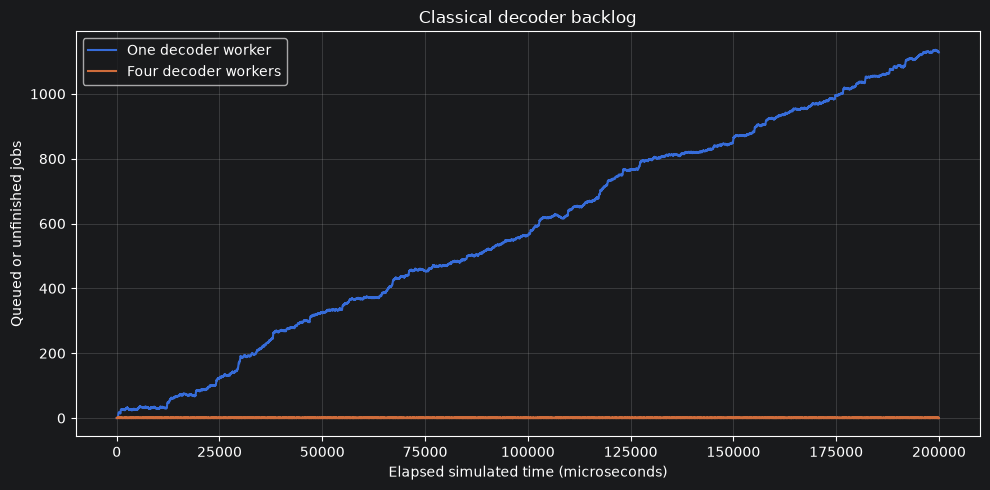

In [37]:
# Plot queue growth
PLOT_JOBS = 20_000

figure, axis = plt.subplots(
    figsize=(10, 5)
)

axis.plot(
    one_worker_queue_df[
        "arrival_time_microseconds"
    ].iloc[:PLOT_JOBS],
    one_worker_queue_df[
        "backlog_at_arrival"
    ].iloc[:PLOT_JOBS],
    linewidth=1.5,
    label="One decoder worker",
)

axis.plot(
    four_worker_queue_df[
        "arrival_time_microseconds"
    ].iloc[:PLOT_JOBS],
    four_worker_queue_df[
        "backlog_at_arrival"
    ].iloc[:PLOT_JOBS],
    linewidth=1.5,
    label="Four decoder workers",
)

axis.set_xlabel(
    "Elapsed simulated time "
    "(microseconds)"
)

axis.set_ylabel(
    "Queued or unfinished jobs"
)

axis.set_title(
    "Classical decoder backlog"
)

axis.grid(
    True,
    alpha=0.3,
)

axis.legend()

figure.tight_layout()

backlog_path = (
    FIGURE_DIR
    / "decoder_backlog_comparison.png"
)

figure.savefig(
    backlog_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

In [38]:
# Parameter sweep
# Sweep arrival intervals and worker counts
SWEEP_JOBS = 20_000

sweep_service_times = queue_service_times[
    :SWEEP_JOBS
]

queue_sweep_results = []

In [39]:
# Run
for arrival_interval in (
    arrival_intervals
):
    for worker_count in (
        worker_counts
    ):
        deadline = (
            2.0
            * arrival_interval
        )

        queue_df = simulate_decoder_queue(
            service_times_microseconds=(
                sweep_service_times
            ),
            arrival_interval_microseconds=(
                arrival_interval
            ),
            number_of_workers=worker_count,
            deadline_microseconds=deadline,
        )

        queue_summary = summarise_queue(
            queue_df
        )

        utilisation = (
            calculate_worker_utilisation(
                mean_service_time_microseconds=(
                    mean_service_time
                ),
                arrival_interval_microseconds=(
                    arrival_interval
                ),
                number_of_workers=worker_count,
            )
        )

        backlog = (
            calculate_backlog_at_arrivals(
                queue_df
            )
        )

        queue_sweep_results.append(
            {
                "arrival_interval_microseconds": (
                    arrival_interval
                ),
                "arrival_rate_per_second": (
                    1e6
                    / arrival_interval
                ),
                "workers": worker_count,
                "deadline_microseconds": (
                    deadline
                ),
                "utilisation_per_worker": (
                    utilisation
                ),
                "analytically_stable": (
                    utilisation < 1.0
                ),
                "maximum_backlog": int(
                    backlog.max()
                ),
                "final_backlog": int(
                    backlog[-1]
                ),
                **queue_summary,
            }
        )

In [40]:
# Table
queue_sweep_df = pd.DataFrame(
    queue_sweep_results
)

queue_sweep_df[
    [
        "arrival_interval_microseconds",
        "workers",
        "utilisation_per_worker",
        "analytically_stable",
        "maximum_backlog",
        "deadline_miss_rate",
        "p99_response_time_microseconds",
    ]
]

,arrival_interval_microseconds,workers,utilisation_per_worker,analytically_stable,maximum_backlog,deadline_miss_rate,p99_response_time_microseconds
0,0.5,1,21.171361,False,19026,1.00000,199900.224299
1,0.5,2,10.585680,False,18082,1.00000,95002.282232
2,0.5,4,5.292840,False,16269,1.00000,42554.020295
3,0.5,8,2.646420,False,12472,1.00000,16330.718585
4,0.5,16,1.323210,False,4933,1.00000,3222.297686
5,1.0,1,10.585680,False,18082,1.00000,190000.719299
6,1.0,2,5.292840,False,16268,1.00000,85102.976301
7,1.0,4,2.646420,False,12469,1.00000,32655.696768
8,1.0,8,1.323210,False,4926,1.00000,6434.307726
9,1.0,16,0.661605,True,17,1.00000,29.399991


In [41]:
# Heatmaps
# Plot deadline-miss rate
deadline_miss_pivot = (
    queue_sweep_df.pivot(
        index="workers",
        columns=(
            "arrival_interval_microseconds"
        ),
        values="deadline_miss_rate",
    )
)

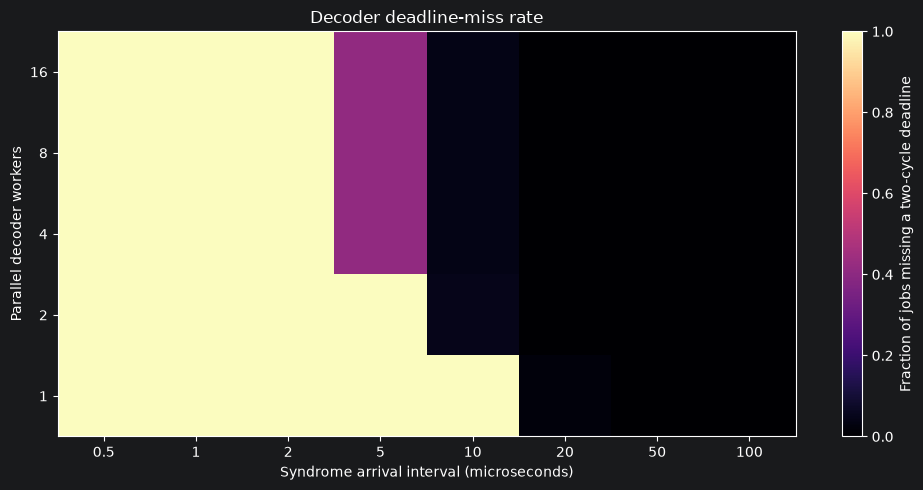

In [42]:
# Plot
figure, axis = plt.subplots(
    figsize=(10, 5)
)

image = axis.imshow(
    deadline_miss_pivot.to_numpy(),
    aspect="auto",
    origin="lower",
    cmap="magma",
    vmin=0.0,
    vmax=1.0,
)

axis.set_xticks(
    np.arange(
        len(
            deadline_miss_pivot.columns
        )
    )
)

axis.set_xticklabels(
    [
        f"{value:g}"
        for value in (
            deadline_miss_pivot.columns
        )
    ]
)

axis.set_yticks(
    np.arange(
        len(
            deadline_miss_pivot.index
        )
    )
)

axis.set_yticklabels(
    deadline_miss_pivot.index
)

axis.set_xlabel(
    "Syndrome arrival interval "
    "(microseconds)"
)

axis.set_ylabel(
    "Parallel decoder workers"
)

axis.set_title(
    "Decoder deadline-miss rate"
)

colour_bar = figure.colorbar(
    image,
    ax=axis,
)

colour_bar.set_label(
    "Fraction of jobs missing "
    "a two-cycle deadline"
)

figure.tight_layout()

deadline_heatmap_path = (
    FIGURE_DIR
    / "decoder_deadline_miss_heatmap.png"
)

figure.savefig(
    deadline_heatmap_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

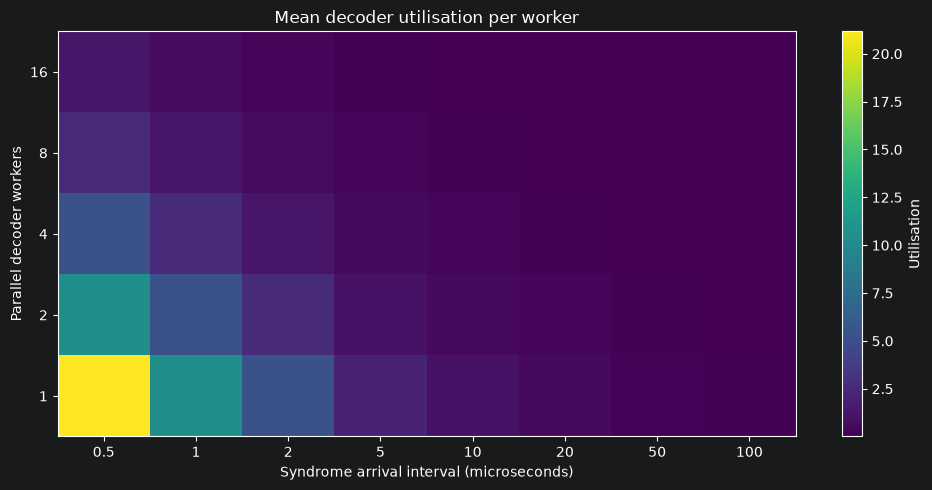

In [43]:
# Plot utilisation
utilisation_pivot = (
    queue_sweep_df.pivot(
        index="workers",
        columns=(
            "arrival_interval_microseconds"
        ),
        values="utilisation_per_worker",
    )
)

figure, axis = plt.subplots(
    figsize=(10, 5)
)

image = axis.imshow(
    utilisation_pivot.to_numpy(),
    aspect="auto",
    origin="lower",
    cmap="viridis",
)

axis.set_xticks(
    np.arange(
        len(
            utilisation_pivot.columns
        )
    )
)

axis.set_xticklabels(
    [
        f"{value:g}"
        for value in (
            utilisation_pivot.columns
        )
    ]
)

axis.set_yticks(
    np.arange(
        len(
            utilisation_pivot.index
        )
    )
)

axis.set_yticklabels(
    utilisation_pivot.index
)

axis.set_xlabel(
    "Syndrome arrival interval "
    "(microseconds)"
)

axis.set_ylabel(
    "Parallel decoder workers"
)

axis.set_title(
    "Mean decoder utilisation per worker"
)

colour_bar = figure.colorbar(
    image,
    ax=axis,
)

colour_bar.set_label(
    "Utilisation"
)

figure.tight_layout()

utilisation_heatmap_path = (
    FIGURE_DIR
    / "decoder_utilisation_heatmap.png"
)

figure.savefig(
    utilisation_heatmap_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

In [44]:
# Export all results
batch_timing_path = (
    RESULTS_DIR
    / "decoder_batch_timing.csv"
)

batch_timing_df.to_csv(
    batch_timing_path,
    index=False,
)

single_shot_latency_path = (
    RESULTS_DIR
    / "decoder_single_shot_latency.csv"
)

single_shot_latency_df.to_csv(
    single_shot_latency_path,
    index=False,
)

event_latency_summary_path = (
    RESULTS_DIR
    / "decoder_event_latency_summary.csv"
)

event_latency_summary_df.to_csv(
    event_latency_summary_path,
    index=False,
)

utilisation_path = (
    RESULTS_DIR
    / "decoder_utilisation.csv"
)

utilisation_df.to_csv(
    utilisation_path,
    index=False,
)

minimum_workers_path = (
    RESULTS_DIR
    / "decoder_minimum_workers.csv"
)

minimum_workers_df.to_csv(
    minimum_workers_path,
    index=False,
)

queue_sweep_path = (
    RESULTS_DIR
    / "decoder_queue_sweep.csv"
)

queue_sweep_df.to_csv(
    queue_sweep_path,
    index=False,
)

latency_summary_df = pd.DataFrame(
    [
        {
            "code": (
                "surface_code:"
                "rotated_memory_x"
            ),
            "distance": CODE_DISTANCE,
            "rounds": SYNDROME_ROUNDS,
            "physical_error_probability": (
                PHYSICAL_ERROR_PROBABILITY
            ),
            **batch_timing_summary,
            **latency_summary,
            "pearson_event_latency_correlation": (
                pearson_correlation
            ),
            "spearman_event_latency_correlation": (
                spearman_correlation
            ),
        }
    ]
)

latency_summary_path = (
    RESULTS_DIR
    / "decoder_latency_summary.csv"
)

latency_summary_df.to_csv(
    latency_summary_path,
    index=False,
)

print(
    f"Saved latency summary to: "
    f"{latency_summary_path}"
)

print(
    f"Saved queue sweep to: "
    f"{queue_sweep_path}"
)

Saved latency summary to: C:\Users\Karthi\Qauntum\results\decoder_latency_summary.csv
Saved queue sweep to: C:\Users\Karthi\Qauntum\results\decoder_queue_sweep.csv


# Decoder Latency and Backlog Results

### Batch Throughput vs. Single-Shot Latency
Batch decoding achieved a substantially lower per-shot execution time than repeated single-shot calls. Whereas batch execution amortised Python interpreter and library-call overhead across many detector samples, the single-shot benchmark exposed per-call invocation overhead and operating-system scheduling variability.

### Tail Latency and Syndrome Complexity
* **Heavy-Tailed Distributions:** The single-shot latency distribution consisted of a compact central mode accompanied by a long upper tail. Consequently, mean service time alone was insufficient to characterise real-time feasibility; the $95\text{th}$-, $99\text{th}$-, and $99.9\text{th}$-percentile latencies were essential to capture worst-case decoding behaviour.
* **Detector Density Correlation:** The relationship between detection-event count and decode latency was evaluated using both Pearson and Spearman correlation coefficients. A positive correlation indicates that denser detector samples generally demand more classical processing, though the spatial and temporal geometry of detection events across the matching graph also governs decoding difficulty.

### Queue Stability and Backlog Dynamics
For $c$ parallel decoder workers, mean system utilisation $\rho$ was defined as:

$$
\rho = \frac{\mathbb{E}[S]}{c \cdot \tau_{\mathrm{arr}}}
$$

where $\mathbb{E}[S]$ is the mean service time and $\tau_{\mathrm{arr}}$ is the syndrome-window arrival interval.

* **Stability vs. Overload:** Configurations with $\rho > 1$ were analytically unstable, as syndrome jobs arrived faster than the worker pool could clear them. Discrete-event simulations confirmed that overloaded regimes developed unbounded backlog growth and diverging response times.
* **Parallelism and Tail-Induced Misses:** Adding parallel decoder workers reduced $\rho$ and stabilised the average queue length, but queue stability alone did not guarantee compliance with strict latency bounds. Deadline misses were governed by both average load and service-time variance—even under-utilised configurations ($\rho < 1$) missed tight deadlines when tail-latency events occurred.

### Hardware Architecture Implications
These benchmarks reflect PyMatching executed via Python on a host CPU and do not directly predict dedicated GPU, FPGA, or ASIC decoder performance. FPGAs and ASICs require far less control logic—such as deep instruction pipelines, branch predictors, out-of-order execution schedulers, and cache coherence—than general-purpose CPUs. In addition, an FPGA or ASIC hardwires the algorithm directly into logic gates and state machines, executing the computation natively on every clock edge without instruction-stream overhead. Nevertheless, the framework isolates the critical performance targets that specialised hardware accelerators must improve:
* Mean service time and upper-tail latency;
* Sustainable streaming throughput and worker concurrency;
* Host-to-accelerator communication overhead.

A complete quantum-classical system model should additionally incorporate syndrome-transfer latency, data serialisation/formatting, correction-frame transmission, control-electronics response time, and feedback dependencies across consecutive QEC rounds.

